# Final e2e sweep: contrast and SR vs magnitude

Results of `sweep_final.py` (`results/WFSW/sweep_final_20261108`), z = 30°, seeing 0.9" along the line of sight, magnitudes 7-12 (900 nm).

- **Main figures**: single stage (rMod 1 and 2; WFS at 900 nm for 550 nm, at 1300 nm for 1650 nm), fusion (unmodulated 900 nm + rMod 2 at 1300 nm) and fusion swapped (unmodulated 1300 nm + rMod 2 at 900 nm, chromatic only). Points: mean over the 10 replays (seed and wind directions changed, 5 s) of the configuration selected at that magnitude; error bars: std over the converged replays; `n/N` where runaways were excluded.
- **Equal-flux figures**: both pyramids at one wavelength, 400 nm band split unmod / mod. Not replayed: every curve there, references included, is the sweep value on the nominal realization (paired comparison).
- Comparison panels (lower rows): contrast as a ratio, SR as a difference, over / minus the single stage with rMod 1. rMod 0 was swept and replayed too, not shown. Contrast: mean raw contrast in 2-5 λ/D relative to the integrated AO peak; hollow markers: science SR < 0.25. Dashed / dotted lines: perfect-coronagraph fitting floors at the same conditions.
- **Radial profiles**: raw contrast vs separation at one magnitude (`MAG`), single rMod 1, single rMod 2 (dashed) and best fusion, replay mean ± std, with the perfect-coronagraph bounds: fitting, and fitting + chromatism for a WFS at 900 or 1300 nm.
- **Single rMod 1 vs best fusion**: at each magnitude the fusion (fusion / swapped) with the lowest replay-mean contrast in the panel band against the single stage with rMod 1, contrast and SR (same runs), marker of the winning fusion; single rMod 2 dashed for reference; lower row: contrast fusion / single, SR fusion − single (green: rMod 1, red: rMod 2). Table of every panel and magnitude at the end.
- Same y range in every contrast panel and in every SR panel.
- Missing cases (still running, or not simulated: achromatic swapped fusion and achromatic 1300 nm single stage) are listed under each figure.

In [1]:
%load_ext autoreload
%autoreload 2
import os.path as op
import pandas as pd
import matplotlib.pyplot as plt
import final_sweep_results as fr

SAVE = False   # True: write the figures as PDF next to the results (fr.OUT)

def show(fig, name):
    if SAVE:
        fig.savefig(op.join(fr.OUT, name + '.pdf'), bbox_inches='tight')
    plt.show()

## Contrast: single, fusion, fusion swapped

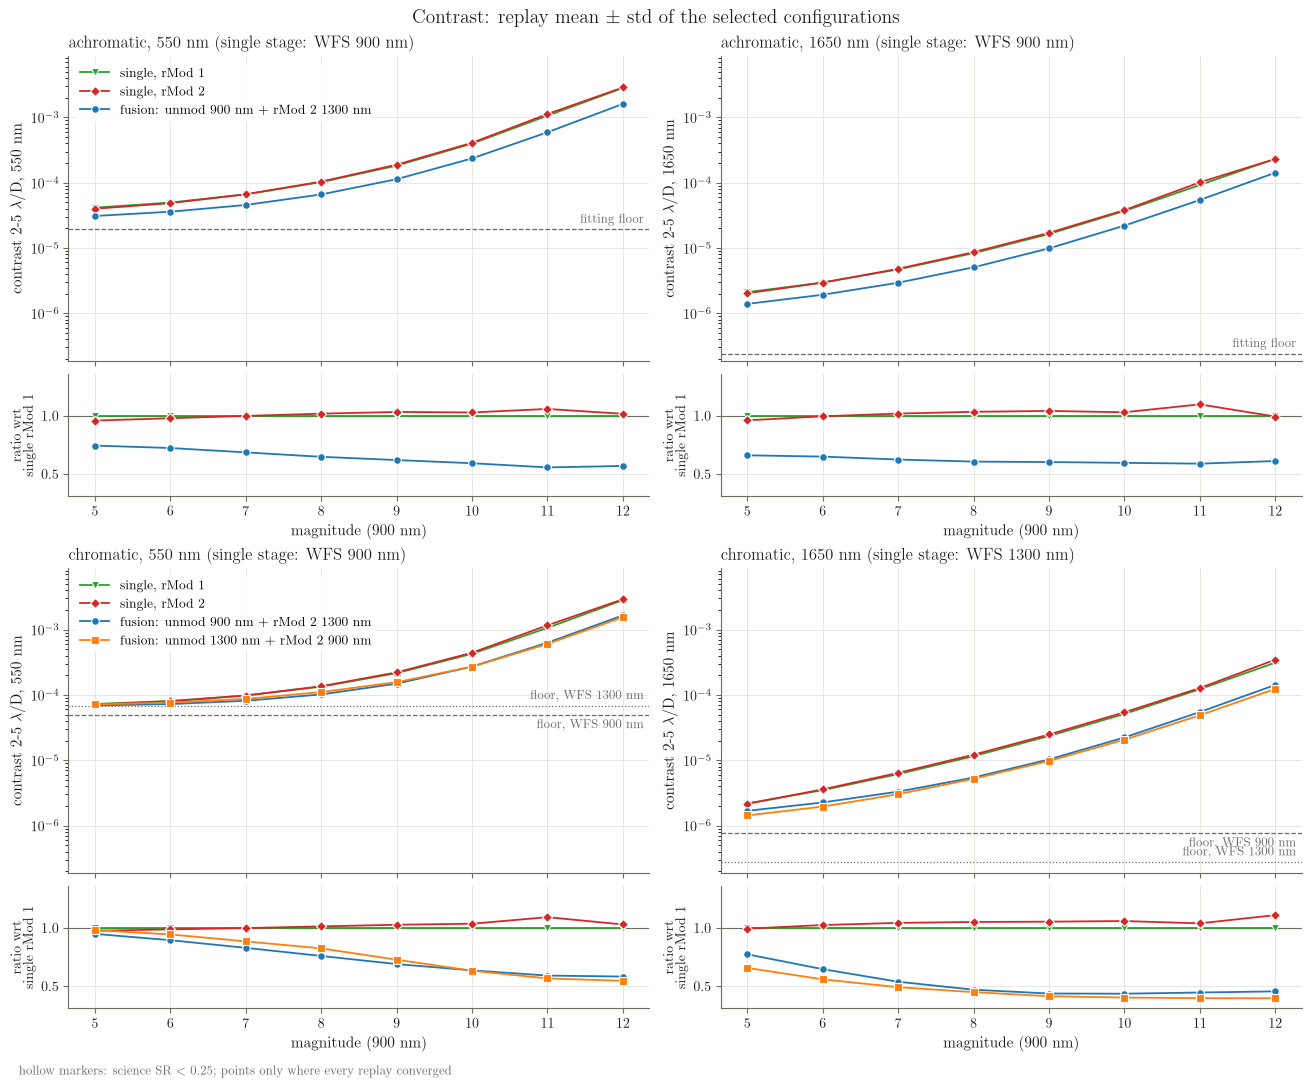

panel,comparison,min,mag of min,max,mag of max,n
"achromatic, 550 nm","single, rMod 2 / single rMod 1",0.960,5,1.060,11,8
"achromatic, 550 nm",fusion: unmod 900 nm + rMod 2 1300 nm / single rMod 1,0.557,11,0.745,5,8
"achromatic, 1650 nm","single, rMod 2 / single rMod 1",0.962,5,1.099,11,8
"achromatic, 1650 nm",fusion: unmod 900 nm + rMod 2 1300 nm / single rMod 1,0.590,11,0.662,5,8
"chromatic, 550 nm","single, rMod 2 / single rMod 1",0.978,5,1.094,11,8
"chromatic, 550 nm",fusion: unmod 900 nm + rMod 2 1300 nm / single rMod 1,0.584,12,0.950,5,8
"chromatic, 550 nm",fusion: unmod 1300 nm + rMod 2 900 nm / single rMod 1,0.547,12,0.983,5,8
"chromatic, 1650 nm","single, rMod 2 / single rMod 1",0.996,5,1.112,12,8
"chromatic, 1650 nm",fusion: unmod 900 nm + rMod 2 1300 nm / single rMod 1,0.437,10,0.775,5,8
"chromatic, 1650 nm",fusion: unmod 1300 nm + rMod 2 900 nm / single rMod 1,0.397,12,0.658,5,8


In [2]:
show(fr.plot_main('contrast'), 'contrast_vs_mag')
fr.cmp_range()   # min-max of the comparison rows (contrast: ratio, SR: difference)

## SR: single, fusion, fusion swapped

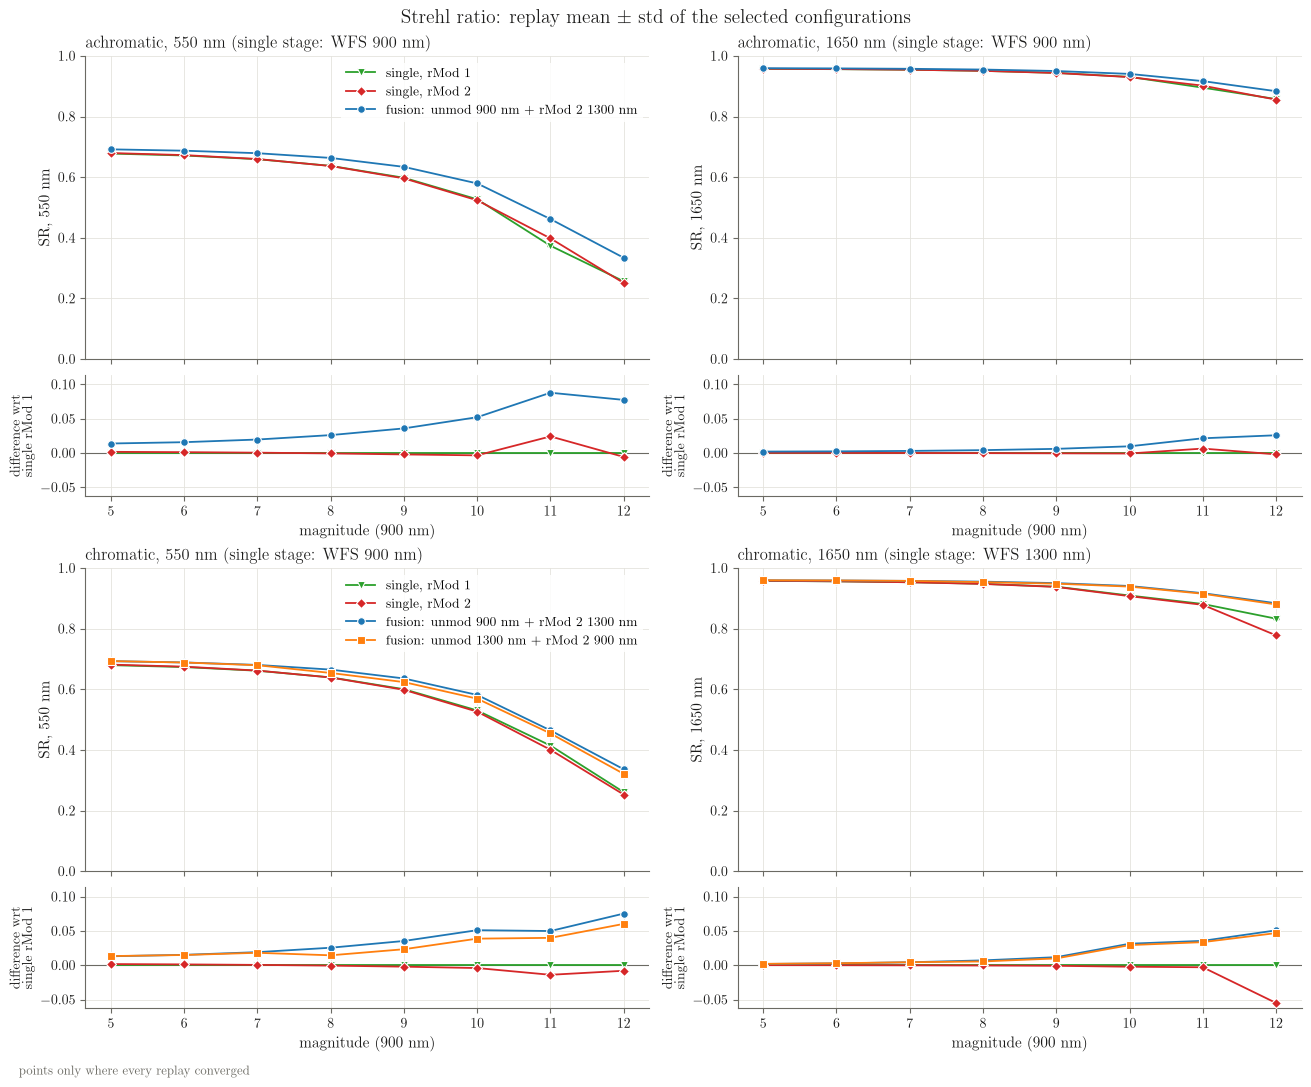

panel,comparison,min,mag of min,max,mag of max,n
"achromatic, 550 nm","single, rMod 2 - single rMod 1",-0.0056,12,+0.0243,11,8
"achromatic, 550 nm",fusion: unmod 900 nm + rMod 2 1300 nm - single rMod 1,+0.0139,5,+0.0880,11,8
"achromatic, 1650 nm","single, rMod 2 - single rMod 1",-0.0019,12,+0.0065,11,8
"achromatic, 1650 nm",fusion: unmod 900 nm + rMod 2 1300 nm - single rMod 1,+0.0022,5,+0.0259,12,8
"chromatic, 550 nm","single, rMod 2 - single rMod 1",-0.0139,11,+0.0018,5,8
"chromatic, 550 nm",fusion: unmod 900 nm + rMod 2 1300 nm - single rMod 1,+0.0132,5,+0.0754,12,8
"chromatic, 550 nm",fusion: unmod 1300 nm + rMod 2 900 nm - single rMod 1,+0.0134,5,+0.0604,12,8
"chromatic, 1650 nm","single, rMod 2 - single rMod 1",-0.0549,12,+0.0002,5,8
"chromatic, 1650 nm",fusion: unmod 900 nm + rMod 2 1300 nm - single rMod 1,+0.0019,5,+0.0509,12,8
"chromatic, 1650 nm",fusion: unmod 1300 nm + rMod 2 900 nm - single rMod 1,+0.0021,5,+0.0469,12,8


In [3]:
show(fr.plot_main('sr'), 'sr_vs_mag')
fr.cmp_range()   # min-max of the comparison rows (contrast: ratio, SR: difference)

## Equal-flux dual: contrast of each band split

In [4]:
# show(fr.plot_equal_flux('contrast'), 'equal_flux_contrast_vs_mag')

## Equal-flux dual: SR of each band split

In [5]:
# show(fr.plot_equal_flux('sr'), 'equal_flux_sr_vs_mag')

## Radial contrast profiles at one magnitude

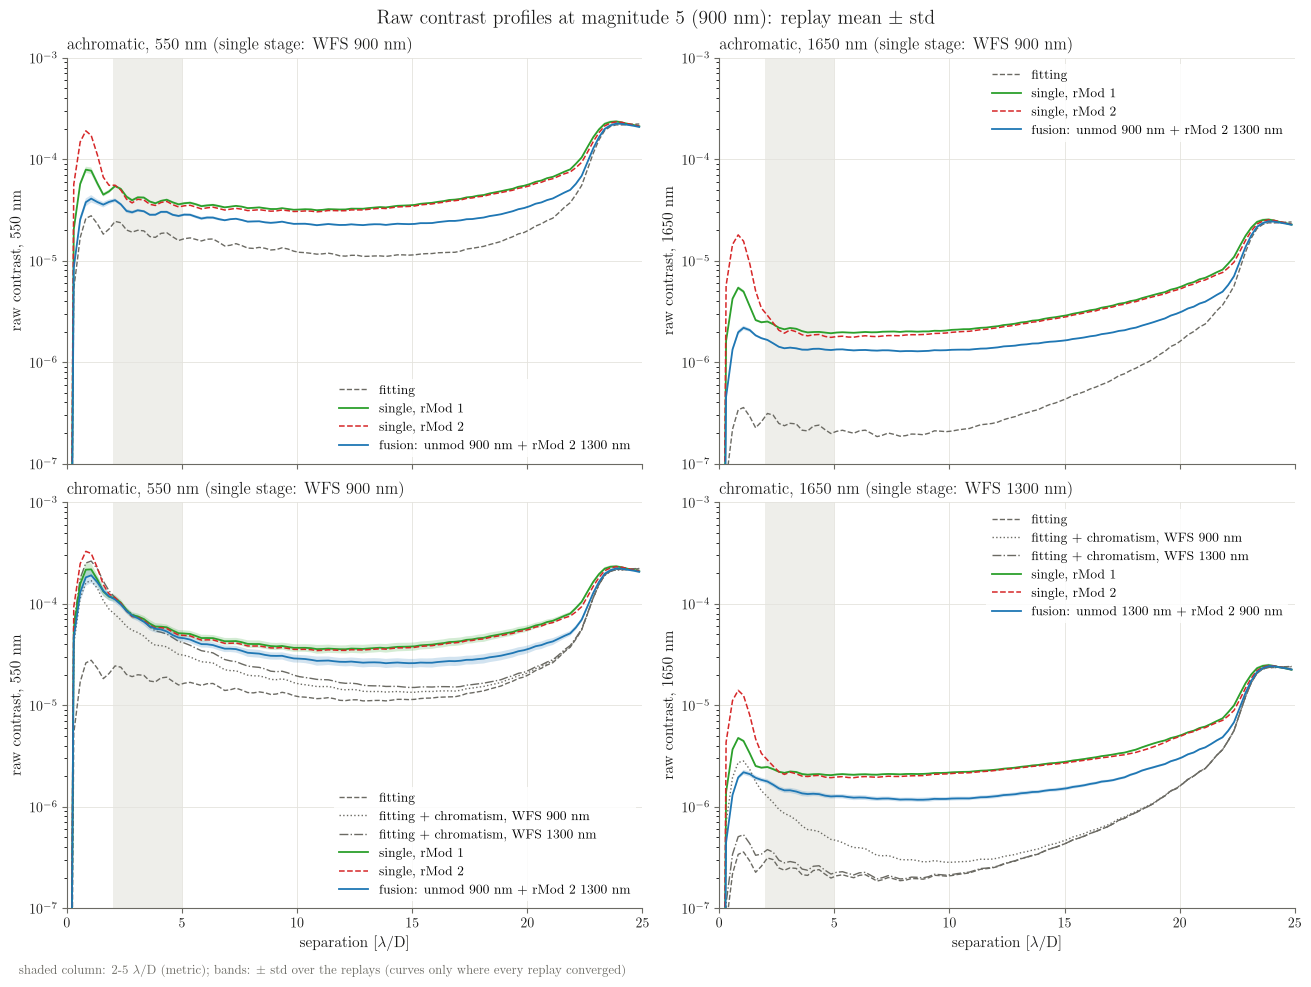

,chromatic,band,single,fusion,contrast single,contrast fusion,contrast single/fusion,SR single,SR fusion,SR fusion-single,data
0,False,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,4.153e-05,3.094e-05,1.342,0.6780,0.6919,+0.0139,10 replays / 10 replays
1,False,1650 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,2.108e-06,1.394e-06,1.512,0.9574,0.9596,+0.0022,10 replays / 10 replays
2,True,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,7.261e-05,6.901e-05,1.052,0.6801,0.6933,+0.0132,10 replays / 10 replays
3,True,1650 nm,"single, rMod 1",fusion: unmod 1300 nm + rMod 2 900 nm,2.166e-06,1.426e-06,1.519,0.9581,0.9602,+0.0021,10 replays / 10 replays


In [13]:
MAG = 5.0   # 900 nm magnitude of the profiles
show(fr.plot_profiles(MAG,rmax=25), f'profiles_mag{MAG:g}')
# single rMod 1 vs best fusion of each panel: contrast single/fusion > 1, SR fusion-single > 0 -> the fusion is better
fr.best_pair_table(MAG)

## Numbers behind the main figures (replay mean, std, converged runs, runaway TNs)

In [7]:
tab = pd.DataFrame(fr.table('contrast')).merge(pd.DataFrame(fr.table('sr')), on=['chromatic', 'band', 'curve', 'case', 'mag', 'n_ok', 'n', 'runaways'],
                                              suffixes=('_contrast', '_sr'))
tab[['chromatic', 'band', 'curve', 'mag', 'mean_contrast', 'std_contrast', 'mean_sr', 'std_sr', 'n_ok', 'n', 'runaways']]

,chromatic,band,curve,mag,mean_contrast,std_contrast,mean_sr,std_sr,n_ok,n,runaways
0,False,550 nm,"single, rMod 1",5.0,0.000042,9.156624e-07,0.677983,0.002077,10,10,
1,False,550 nm,"single, rMod 1",6.0,0.000050,9.198898e-07,0.671642,0.002060,10,10,
2,False,550 nm,"single, rMod 1",7.0,0.000066,1.024793e-06,0.659475,0.002016,10,10,
3,False,550 nm,"single, rMod 1",8.0,0.000102,1.082202e-06,0.637442,0.001997,10,10,
4,False,550 nm,"single, rMod 1",9.0,0.000182,1.537359e-06,0.598186,0.001971,10,10,
...,...,...,...,...,...,...,...,...,...,...,...
107,True,1650 nm,fusion: unmod 1300 nm + rMod 2 900 nm,8.0,0.000005,1.720307e-07,0.953927,0.000426,10,10,
108,True,1650 nm,fusion: unmod 1300 nm + rMod 2 900 nm,9.0,0.000010,2.581155e-07,0.948884,0.000470,10,10,
109,True,1650 nm,fusion: unmod 1300 nm + rMod 2 900 nm,10.0,0.000021,4.245633e-07,0.939159,0.000507,10,10,
110,True,1650 nm,fusion: unmod 1300 nm + rMod 2 900 nm,11.0,0.000049,8.137725e-07,0.915654,0.000655,10,10,


## Single stage rMod 1 vs best fusion: contrast

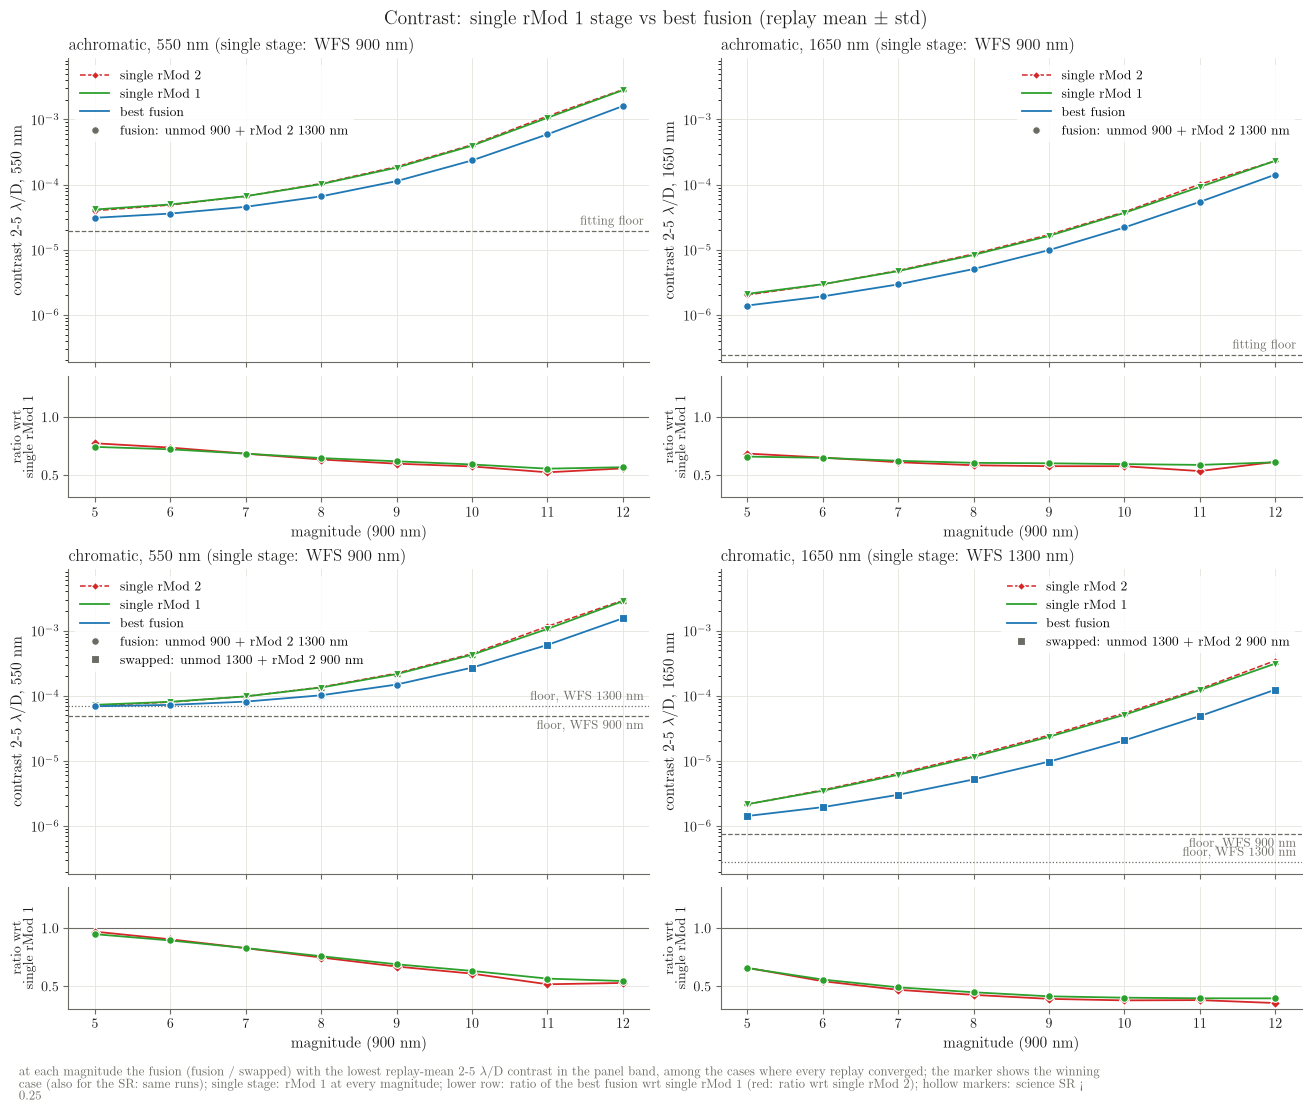

panel,comparison,min,mag of min,max,mag of max,n
"achromatic, 550 nm",best fusion / single rMod 2,0.526,11,0.776,5,8
"achromatic, 550 nm",best fusion / single rMod 1,0.557,11,0.745,5,8
"achromatic, 1650 nm",best fusion / single rMod 2,0.537,11,0.688,5,8
"achromatic, 1650 nm",best fusion / single rMod 1,0.590,11,0.662,5,8
"chromatic, 550 nm",best fusion / single rMod 2,0.519,11,0.972,5,8
"chromatic, 550 nm",best fusion / single rMod 1,0.547,12,0.950,5,8
"chromatic, 1650 nm",best fusion / single rMod 2,0.358,12,0.661,5,8
"chromatic, 1650 nm",best fusion / single rMod 1,0.397,12,0.658,5,8


In [8]:
# best fusion (fusion / swapped) selected on the 2-5 λ/D contrast at each magnitude; single rMod 1, rMod 2 dashed
show(fr.plot_best('contrast'), 'r1_vs_fusion_contrast_vs_mag')
fr.cmp_range()   # min-max of the comparison rows (contrast: ratio, SR: difference)

## Single stage rMod 1 vs best fusion: SR (same runs as the contrast figure)

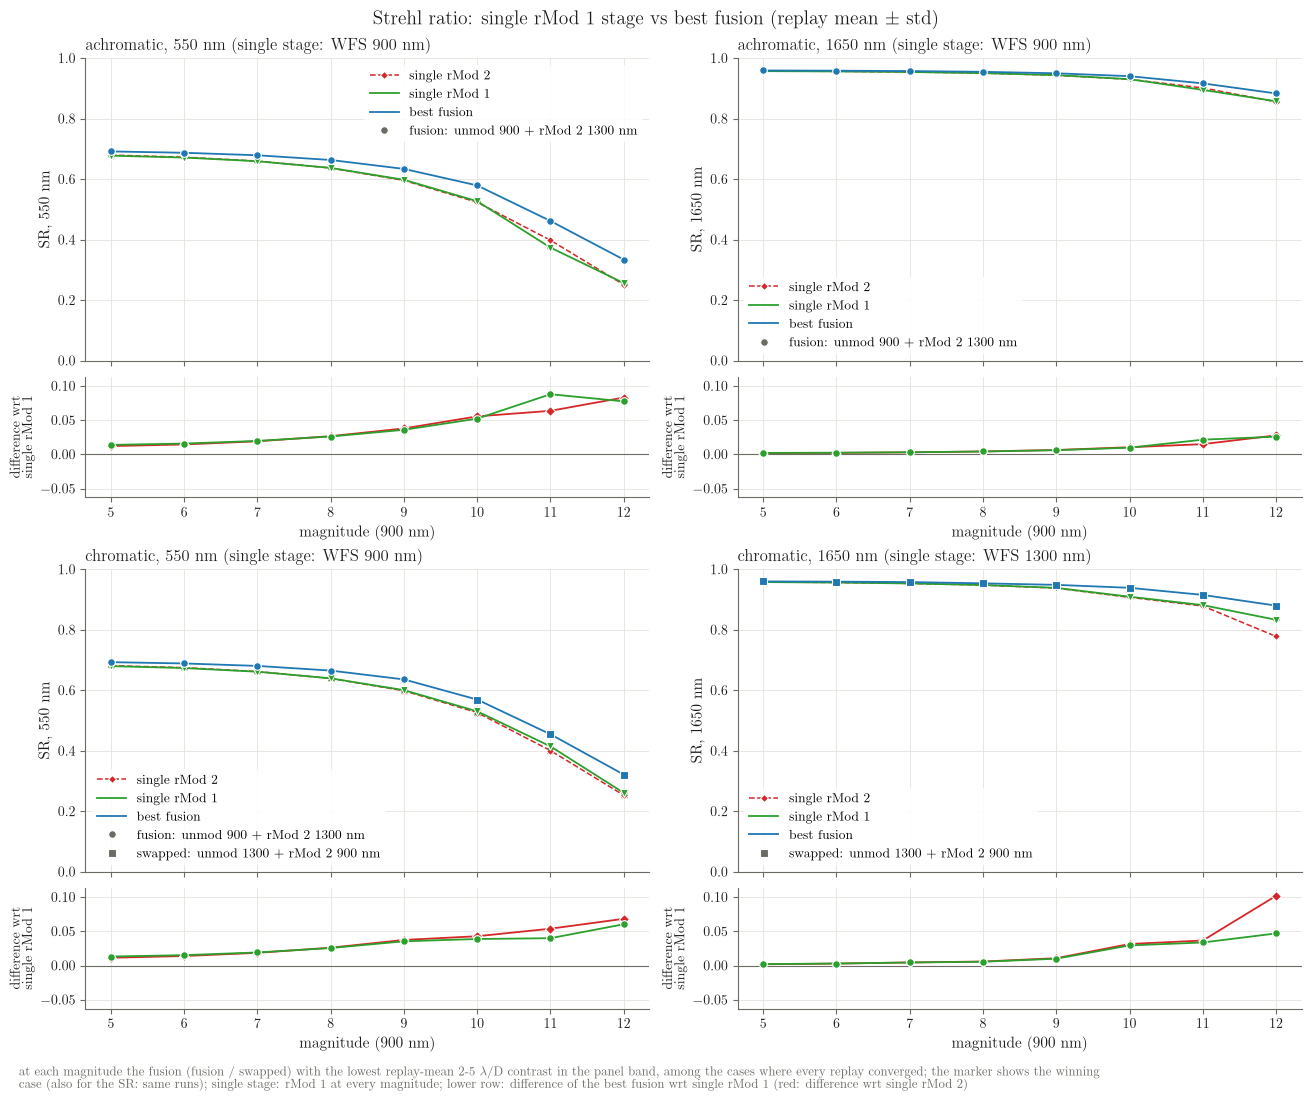

panel,comparison,min,mag of min,max,mag of max,n
"achromatic, 550 nm",best fusion - single rMod 2,+0.0122,5,+0.0831,12,8
"achromatic, 550 nm",best fusion - single rMod 1,+0.0139,5,+0.0880,11,8
"achromatic, 1650 nm",best fusion - single rMod 2,+0.0019,5,+0.0278,12,8
"achromatic, 1650 nm",best fusion - single rMod 1,+0.0022,5,+0.0259,12,8
"chromatic, 550 nm",best fusion - single rMod 2,+0.0114,5,+0.0684,12,8
"chromatic, 550 nm",best fusion - single rMod 1,+0.0132,5,+0.0604,12,8
"chromatic, 1650 nm",best fusion - single rMod 2,+0.0019,5,+0.1019,12,8
"chromatic, 1650 nm",best fusion - single rMod 1,+0.0021,5,+0.0469,12,8


In [9]:
show(fr.plot_best('sr'), 'r1_vs_fusion_sr_vs_mag')
fr.cmp_range()   # min-max of the comparison rows (contrast: ratio, SR: difference)

## Single stage rMod 1 vs best fusion: every panel and magnitude

In [10]:
# contrast single/fusion > 1 and SR fusion-single > 0: the fusion is better
fr.best_pair_table(fr.MAGS)

,mag,chromatic,band,single,fusion,contrast single,contrast fusion,contrast single/fusion,SR single,SR fusion,SR fusion-single,data
0,5.0,False,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,4.153e-05,3.094e-05,1.342,0.6780,0.6919,+0.0139,10 replays / 10 replays
1,5.0,False,1650 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,2.108e-06,1.394e-06,1.512,0.9574,0.9596,+0.0022,10 replays / 10 replays
2,5.0,True,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,7.261e-05,6.901e-05,1.052,0.6801,0.6933,+0.0132,10 replays / 10 replays
3,5.0,True,1650 nm,"single, rMod 1",fusion: unmod 1300 nm + rMod 2 900 nm,2.166e-06,1.426e-06,1.519,0.9581,0.9602,+0.0021,10 replays / 10 replays
4,6.0,False,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,4.963e-05,3.594e-05,1.381,0.6716,0.6875,+0.0158,10 replays / 10 replays
5,6.0,False,1650 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,2.959e-06,1.925e-06,1.537,0.9564,0.9589,+0.0025,10 replays / 10 replays
6,6.0,True,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,8.080e-05,7.244e-05,1.116,0.6738,0.6890,+0.0152,10 replays / 10 replays
7,6.0,True,1650 nm,"single, rMod 1",fusion: unmod 1300 nm + rMod 2 900 nm,3.483e-06,1.950e-06,1.786,0.9565,0.9595,+0.0030,10 replays / 10 replays
8,7.0,False,550 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,6.644e-05,4.562e-05,1.456,0.6595,0.6792,+0.0197,10 replays / 10 replays
9,7.0,False,1650 nm,"single, rMod 1",fusion: unmod 900 nm + rMod 2 1300 nm,4.703e-06,2.940e-06,1.599,0.9545,0.9576,+0.0031,10 replays / 10 replays
